In [1]:
import numpy as np
import pandas as pd
import math
from uncertainties import unumpy as unp
from uncertainties import ufloat as uf
import numpy as np
import uncertainties.umath as umath
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
def plot_power_law(x, y, xlabel=None, ylabel=None, title=None):
    """Log-log scatter plot of x vs y with a power-law fit y = a * x**b.

    x, y : pandas Series, arrays, or unumpy arrays of ufloats
           (only nominal values are used for the fit; values must be > 0)

    Returns
    -------
    a, b : ufloat   (prefactor and exponent)
    """
    # Works for plain floats and for ufloat arrays
    x = np.asarray(unp.nominal_values(np.asarray(x).ravel()), dtype=float)
    y = np.asarray(unp.nominal_values(np.asarray(y).ravel()), dtype=float)

    # Linear fit in log space: ln y = b ln x + ln a
    res = stats.linregress(np.log(x), np.log(y))
    b = uf(res.slope, res.stderr)
    ln_a = uf(res.intercept, res.intercept_stderr)
    a = umath.exp(ln_a)

    x_fit = np.linspace(0.9 * x.min(), 1.1 * x.max(), 200)
    y_fit = a.n * x_fit**b.n

    fig, ax = plt.subplots()
    ax.scatter(x, y, label="Data")
    ax.plot(
        x_fit, y_fit, color="red",
        label=f"Fit: y = ({a:.2uP}) x$^{{{b:.2uP}}}$\n"
              f"$R^2$ = {res.rvalue**2:.4f}",
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.9 * x.min(), 1.1 * x.max())
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if title:  ax.set_title(title)
    ax.legend()
    plt.show()

    return a, b

    Run1_Time_s  Run1_Intensity  Run1_Temperature
0           0.0            49.7              88.6
1          10.0            50.0              89.1
2          20.0            49.0              88.0
3          30.0            48.1              86.8
4          40.0            47.2              86.1
..          ...             ...               ...
72        720.0            15.6              50.2
73        730.0            15.6              49.9
74        740.0            15.1              49.5
75        750.0            15.3              49.2
76        760.0            15.0              48.9

[77 rows x 3 columns]


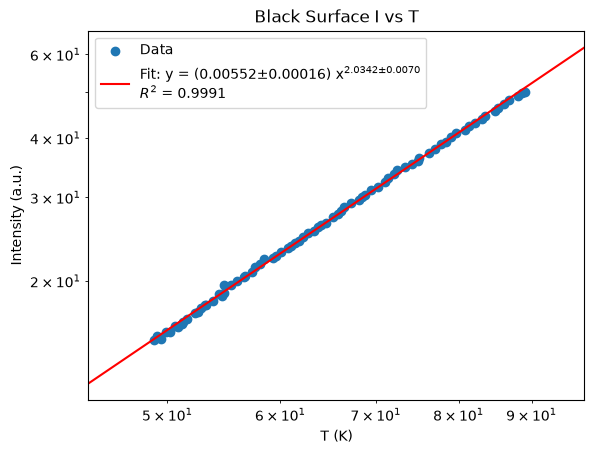

2.034+/-0.007


In [27]:
run_str = "Run1"
df = pd.read_csv("ALLDATA_radianc.csv", usecols=lambda c: run_str in c).dropna(axis=0, how="all")
print(df)

X = df.iloc[:,2].to_numpy()
Y = df.iloc[:,1].to_numpy()

a, power = plot_power_law(X, Y, xlabel="T (K)", ylabel="Intensity (a.u.)", title="Black Surface I vs T")

print(power)

    Run2_Time_s  Run2_Intensity  Run2_Temperature
0           0.0             1.1              48.5
1          10.0             1.4              48.9
2          20.0             1.5              50.1
3          30.0             1.2              51.6
4          40.0             1.2              52.8
5          50.0             1.2              54.1
6          60.0             1.3              55.4
7          70.0             1.4              56.6
8          80.0             1.4              57.7
9          90.0             1.4              58.8
10        100.0             1.6              59.9
11        110.0             1.6              61.0
12        120.0             1.7              61.9
13        130.0             1.9              62.8
14        140.0             1.9              64.3
15        150.0             2.0              65.3
16        160.0             2.0              66.2
17        170.0             2.0              67.2
18        180.0             2.2              68.2


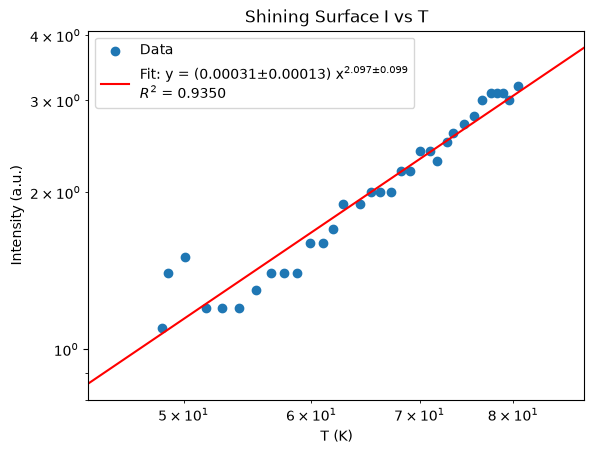

2.10+/-0.10


In [29]:
run_str = "Run2"
df = pd.read_csv("ALLDATA_radianc.csv", usecols=lambda c: run_str in c).dropna(axis=0, how="all")
print(df)

X = df.iloc[:,2].to_numpy()
Y = df.iloc[:,1].to_numpy()

a, power = plot_power_law(X, Y, xlabel="T (K)", ylabel="Intensity (a.u.)", title="Shining Surface I vs T")

print(power)

    Run7_Time_s  Run7_Intensity  Run7_Temperature
0           0.0            40.3              90.6
1          10.0            40.9              90.9
2          20.0            39.9              90.0
3          30.0            39.2              89.1
4          40.0            38.7              88.3
..          ...             ...               ...
73        730.0            13.1              50.9
74        740.0            12.9              50.6
75        750.0            12.8              50.3
76        760.0            12.6              50.1
77        770.0            12.7              49.5

[78 rows x 3 columns]


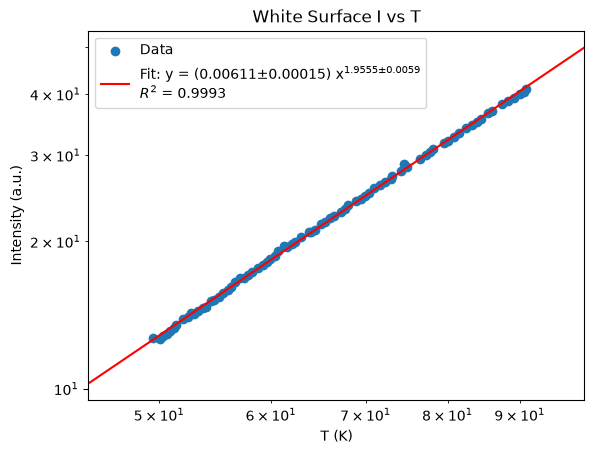

1.956+/-0.006


In [30]:
run_str = "Run7"
df = pd.read_csv("ALLDATA_radianc.csv", usecols=lambda c: run_str in c).dropna(axis=0, how="all")
print(df)

X = df.iloc[:,2].to_numpy()
Y = df.iloc[:,1].to_numpy()

a, power = plot_power_law(X, Y, xlabel="T (K)", ylabel="Intensity (a.u.)", title="White Surface I vs T")

print(power)

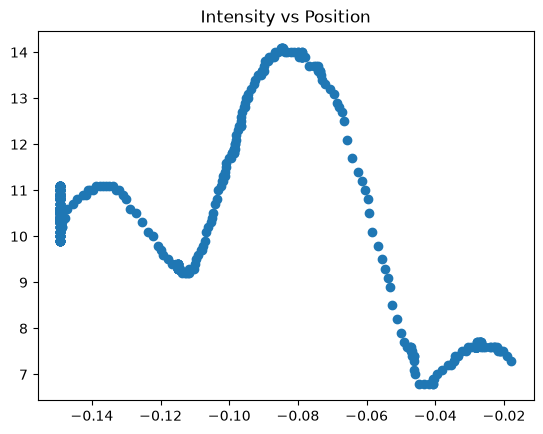

In [50]:
run_str = "Run6"
df = pd.read_csv("ALLDATA_radianc.csv", usecols=lambda c: run_str in c).dropna(axis=0, how="all")

df = df.iloc[100:1000,]


plt.scatter(df["Run6_Pos"], df["Run6_Intensity"])
plt.title("Intensity vs Position")

plt.show()